# 03 - Train and compare the transistor models (Part A, step 2)

Self-contained notebook, built up in parts:

1. **Harness (this part):** data split, source/drain canonicalisation, target transforms, physics features and the metrics used everywhere else, each with a check.
2. Baseline models: polynomial ridge regression and gradient boosting.
3. Neural models (MLP and residual MLP) and the comparison table (4 model types x 4 cases, validation R2, median and 95th-percentile error).
4. Selection of the best model per case, test-set results, predicted-vs-SPICE plots and the four saved model files.

One model per case (NMOS ON, NMOS OFF, PMOS ON, PMOS OFF), each predicting the four terminal currents `id, ig, is, ib`.
Model families to compare: residual MLP, plain MLP, gradient boosting (LightGBM) and polynomial ridge regression (plus extra trees as an optional fifth).
Only the CSV files in `data/` are needed (the symmetry check in section 2 also uses ngspice and the model file, and is skipped if they are missing).

In [1]:
import re
import shutil
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
RESULT_DIR = ROOT / "results"
MODEL_DIR = ROOT / "models"
MODEL_FILE = ROOT / "Model Files-20261105" / "models" / "16nm_HP.pm"
LDIFF = 32e-9                               # AD = AS = W * LDIFF, as in the datasets

CASES = {"nmos_on": "nmos", "nmos_off": "nmos", "pmos_on": "pmos", "pmos_off": "pmos"}
FEATS = ["vdd", "temp", "w", "vd", "vs", "vg", "vb", "vth0", "toxe", "ndep", "u0", "xj"]
TERMS = ["id", "ig", "is", "ib"]            # terminal currents flowing into the device
SPLIT = (0.70, 0.15, 0.15)                  # train / validation / test
SPLIT_SEED = 20261105
I0 = 1e-16                                  # scale of the signed-log transform [A]
REL_FLOOR = 1e-15                           # relative errors are only meaningful above the solver floor [A]
SMALL_VDS = 5e-3                            # |Vds| below this is the "small-Vds" region [V]
KB_Q = 8.617333262e-5                       # k/q [V/K]

data = {c: pd.read_csv(DATA_DIR / f"{c}.csv") for c in CASES}
{c: d.shape for c, d in data.items()}

{'nmos_on': (10000, 16),
 'nmos_off': (10000, 16),
 'pmos_on': (10000, 16),
 'pmos_off': (10000, 16)}

## 1. Split
Random 70 / 15 / 15 split with a fixed seed: 7,000 train, 1,500 validation, 1,500 test rows per case. Models are compared on the validation split;
the test split is only used once, for the chosen model.

In [2]:
def split_indices(n, seed=SPLIT_SEED):
    perm = np.random.default_rng(seed).permutation(n)
    n_tr, n_va = int(SPLIT[0] * n), int(SPLIT[1] * n)
    return perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:]


splits = {c: split_indices(len(d)) for c, d in data.items()}
tr, va, te = splits["nmos_on"]
print("rows per split:", len(tr), len(va), len(te), "| disjoint:", len(set(tr) | set(va) | set(te)) == len(data["nmos_on"]))

rows per split: 7000 1500 1500 | disjoint: True


## 2. Source/drain canonicalisation
The device is symmetric in drain and source (the netlists use `AD = AS`), so swapping the two terminals gives the same device: `id` and `is` trade places and `ig`, `ib` are unchanged.
Drain and source are drawn independently, so half the samples sit in each orientation. Mapping every sample to one orientation (**Vds >= 0 for NMOS, Vsd >= 0 for PMOS**) fixes the sign of `id` and `is` per case, and removes the sign change at Vd = Vs from the learning problem.
The check below compares real SPICE results for the two orientations (nominal process, W = 32 nm).

In [3]:
def canonicalize(df, device):
    """Swap drain and source where needed so that Vds >= 0 (NMOS) or Vsd >= 0 (PMOS); id and is swap with them."""
    d = df.copy()
    swap = (d["vd"] < d["vs"]) if device == "nmos" else (d["vd"] > d["vs"])
    d.loc[swap, ["vd", "vs"]] = d.loc[swap, ["vs", "vd"]].to_numpy()
    d.loc[swap, ["id", "is"]] = d.loc[swap, ["is", "id"]].to_numpy()
    return d, swap


canon, swapped = {}, {}
for c, dev in CASES.items():
    canon[c], swapped[c] = canonicalize(data[c], dev)
print("fraction of rows swapped:", {c: round(float(s.mean()), 3) for c, s in swapped.items()})

# canonicalising twice changes nothing, and the orientation is now fixed
again, _ = canonicalize(canon["nmos_on"], "nmos")
print("idempotent:", bool(again.equals(canon["nmos_on"])))

sign = pd.DataFrame({c: {t: f"{(d[t] > 0).mean():.3f}" for t in TERMS} for c, d in canon.items()})
print("fraction of positive values after canonicalisation:")
sign

fraction of rows swapped: {'nmos_on': 0.505, 'nmos_off': 0.498, 'pmos_on': 0.5, 'pmos_off': 0.498}
idempotent: True
fraction of positive values after canonicalisation:


,nmos_on,nmos_off,pmos_on,pmos_off
id,1.000,1.000,0.000,0.000
ig,1.000,0.000,0.000,0.911
is,0.000,0.572,1.000,0.649
ib,0.000,0.002,1.000,0.732


After canonicalisation the signs of all four currents are fixed in the ON cases. In the OFF cases `is`, `ib` and (PMOS) `ig` still change sign: they are small and set by the balance of the channel, gate and body components. The signed-log target is therefore still needed.

In [4]:
SPICE_OPTIONS = ".options gmin=1e-18 abstol=1e-18 reltol=1e-6 vntol=1e-9"
VDD = 0.9
BIAS = {  # (vg, vb) per case
    "nmos_on": (VDD, 0.0), "nmos_off": (0.0, 0.0), "pmos_on": (0.0, VDD), "pmos_off": (VDD, VDD)}


def run_ngspice(netlist, name="symmetry.cir"):
    build = ROOT / "build"
    build.mkdir(exist_ok=True)
    shutil.copyfile(MODEL_FILE, build / MODEL_FILE.name)
    (build / name).write_text(netlist, newline="\n")
    if shutil.which("ngspice"):
        return subprocess.run(["ngspice", "-b", name], cwd=build, capture_output=True, text=True).stdout
    p = build.resolve()
    wsl = "/mnt/" + p.drive.rstrip(":").lower() + "/" + "/".join(p.parts[1:])
    r = subprocess.run(["wsl", "-e", "bash", "-c", f"cd '{wsl}' && ngspice -b {name} 2>/dev/null"], capture_output=True, text=True)
    return r.stdout.replace("\x00", "")


def symmetry_netlist():
    lines = ["* drain/source symmetry check", f".include {MODEL_FILE.name}", SPICE_OPTIONS]
    runs = []
    for c, dev in CASES.items():
        vg, vb = BIAS[c]
        for k, (vd, vs) in enumerate([(0.5, 0.2), (0.2, 0.5)]):
            t = f"{c}_{k}"
            w = 32e-9
            lines.append(f"M{t} d{t} g{t} s{t} b{t} {dev} W={w:.6g} L=16n AD={w * LDIFF:.6g} AS={w * LDIFF:.6g}")
            lines += [f"Vd{t} d{t} 0 {vd}", f"Vg{t} g{t} 0 {vg}", f"Vs{t} s{t} 0 {vs}", f"Vb{t} b{t} 0 {vb}"]
            runs.append(t)
    lines += [".control", "set numdgt = 15", "set temp = 27", "op"]
    lines += ["print " + " ".join(f"i(v{x}{t})" for x in "dgsb") for t in runs]
    lines += [".endc", ".end", ""]
    return "\n".join(lines), runs


try:
    text, runs = symmetry_netlist()
    out = run_ngspice(text)
    vals = [-float(v) for v in re.findall(r"^i\(v[dgsb]\w*\) = (\S+)$", out, re.M)]
    assert len(vals) == 4 * len(runs), "ngspice did not return all results"
    cur = {t: vals[4 * k:4 * k + 4] for k, t in enumerate(runs)}
    rows = []
    for c in CASES:
        a, b = cur[f"{c}_0"], cur[f"{c}_1"]            # (id, ig, is, ib) before and after swapping drain and source
        rows.append(dict(case=c, id_vs_is_swapped=abs(a[0] - b[2]) / abs(a[0]), is_vs_id_swapped=abs(a[2] - b[0]) / abs(a[2]),
                         ig=abs(a[1] - b[1]) / abs(a[1]), ib=abs(a[3] - b[3]) / abs(a[3])))
    sym = pd.DataFrame(rows).set_index("case")
    print("relative mismatch between the two orientations (0 = perfectly symmetric):")
    display(sym.style.format("{:.1e}"))
except Exception as e:                                  # ngspice or the model file not available
    print("symmetry check skipped:", e)

relative mismatch between the two orientations (0 = perfectly symmetric):


,id_vs_is_swapped,is_vs_id_swapped,ig,ib
case,,,,
nmos_on,1.5e-14,1.7e-14,0.0e+00,1.8e-10
nmos_off,5.3e-08,7.0e-06,0.0e+00,1.9e-05
pmos_on,1.2e-13,1.2e-13,2.7e-15,0.0e+00
pmos_off,1.4e-03,1.7e-04,0.0e+00,0.0e+00


## 3. Target transforms
The currents span about 11 decades and (before canonicalisation) change sign, so the models are trained on a transformed target.

* **Signed log:** `y = arcsinh(I / I0)` with `I0 = 1e-16 A`. For `|I| >> I0` it equals `ln(2|I|/I0)`, so an error in `y` is a relative error in `I`; it is linear near zero and keeps the sign.
* **Vds-aware factor (id and is only):** the BSIM sub-threshold current carries the factor `1 - exp(-Vds / V_therm)` (lecture slide 10), with `V_therm = kT/q`. At `|Vds|` of 1 uV to a few mV, where the ON devices sit inside a gate, the current is proportional to `Vds` and crosses zero. Dividing by the factor leaves a smooth quantity that does not vanish at `Vds -> 0`:
  `y = arcsinh((I / factor) / I0)`, inverted by `I = I0 sinh(y) * factor`.

**Caveat (measured below):** the factor only helps where the current really is proportional to Vds at small Vds. In the ON cases it is; in the OFF cases `id` also contains Vds-independent components (gate-induced and tunnelling currents leaving through the drain), so dividing by the factor over-corrects. Using it is therefore a per-case choice, made on validation.

In [5]:
def vds_factor(vds, temp_c):
    """1 - exp(-|Vds| / vT) with vT = kT/q; expm1 keeps it accurate for tiny Vds."""
    vt = KB_Q * (np.asarray(temp_c) + 273.15)
    return np.clip(-np.expm1(-np.abs(vds) / vt), 1e-12, None)


def encode(currents, vds, temp_c, vds_aware=True):
    """Currents (n, 4) in the order id, ig, is, ib -> transformed targets (n, 4)."""
    cur = np.asarray(currents, dtype=float).copy()
    if vds_aware:
        f = vds_factor(vds, temp_c)
        cur[:, 0] /= f
        cur[:, 2] /= f
    return np.arcsinh(cur / I0)


def decode(y, vds, temp_c, vds_aware=True):
    cur = I0 * np.sinh(np.asarray(y, dtype=float))
    if vds_aware:
        f = vds_factor(vds, temp_c)
        cur[:, 0] *= f
        cur[:, 2] *= f
    return cur


rows = []
for c, dev in CASES.items():
    d = canon[c]
    vds = (d["vd"] - d["vs"]).abs().to_numpy()
    cur = d[TERMS].to_numpy()
    for aware in (False, True):
        back = decode(encode(cur, vds, d["temp"].to_numpy(), aware), vds, d["temp"].to_numpy(), aware)
        m = np.abs(cur) > 0
        rows.append(dict(case=c, vds_aware=aware, max_roundtrip_rel_error=float(np.max(np.abs(back[m] - cur[m]) / np.abs(cur[m])))))
pd.DataFrame(rows)

,case,vds_aware,max_roundtrip_rel_error
0,nmos_on,False,2.099268e-15
1,nmos_on,True,2.089560e-15
2,nmos_off,False,1.960642e-15
3,nmos_off,True,1.996075e-15
4,pmos_on,False,2.084139e-15
5,pmos_on,True,2.125665e-15
6,pmos_off,False,2.009906e-15
7,pmos_off,True,2.180220e-15


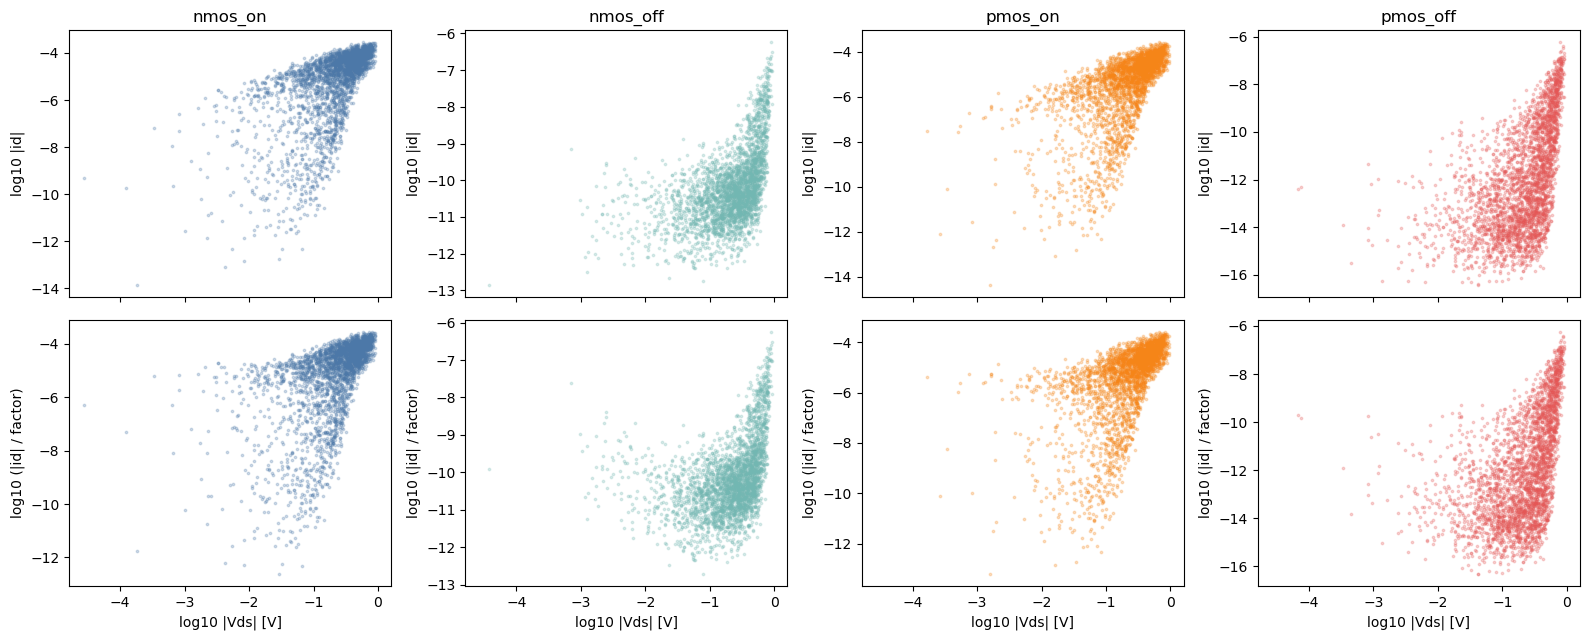

slope of log10|id| vs log10|Vds| for |Vds| < 10 mV (1 = proportional to Vds, 0 = independent of Vds):


,rows_below_10mV,slope_raw,slope_with_factor
case,,,
nmos_on,234,0.730413,-0.217159
nmos_off,238,0.314457,-0.654422
pmos_on,238,0.941118,-0.001043
pmos_off,241,-0.157560,-1.114723


In [6]:
fig, ax = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True)
slopes = []
for k, (c, dev) in enumerate(CASES.items()):
    d = canon[c]
    vds = (d["vd"] - d["vs"]).abs().to_numpy()
    f = vds_factor(vds, d["temp"].to_numpy())
    raw, scaled = np.log10(np.abs(d["id"].to_numpy())), np.log10(np.abs(d["id"].to_numpy()) / f)
    sel = np.random.default_rng(0).choice(len(d), size=3000, replace=False)
    for row, (y, label) in enumerate([(raw, "log10 |id|"), (scaled, "log10 (|id| / factor)")]):
        ax[row, k].scatter(np.log10(vds[sel]), y[sel], s=3, alpha=0.25, color=["#4C78A8", "#72B7B2", "#F58518", "#E45756"][k])
        ax[row, k].set_ylabel(label)
    ax[1, k].set_xlabel("log10 |Vds| [V]")
    ax[0, k].set_title(c)
    small = vds < 10e-3
    slopes.append(dict(case=c, rows_below_10mV=int(small.sum()),
                       slope_raw=np.polyfit(np.log10(vds[small]), raw[small], 1)[0],
                       slope_with_factor=np.polyfit(np.log10(vds[small]), scaled[small], 1)[0]))
fig.tight_layout()
fig.savefig(RESULT_DIR / "vds_aware_target.png", dpi=110)
plt.show()
print("slope of log10|id| vs log10|Vds| for |Vds| < 10 mV (1 = proportional to Vds, 0 = independent of Vds):")
pd.DataFrame(slopes).set_index("case")

Reading the slopes (all other inputs vary freely, so they are rough): in the ON cases the current goes from a clear dependence on Vds (0.73 and 0.94) to almost none with the factor (-0.22 and 0.00). In the OFF cases the raw slope is already weak (0.31 and -0.16), because `id` contains Vds-independent components, and the factor over-corrects (-0.65 and -1.11). So the Vds-aware target is meant for the ON cases and is tested per case for the OFF cases.

## 4. Features
Raw inputs plus quantities built from the known device physics (source-referenced voltages; for PMOS the sign is mirrored so both device types see the same regime):
`q/kT`, `Vgs`, `Vds`, `Vbs`, `Vgd`, the overdrive `(Vgs - Vth)/vT`, `Vds/vT` and `ln W`. Models are free to use either set; the comparison will show which helps.

In [7]:
def make_features(d, device):
    sgn = 1.0 if device == "nmos" else -1.0
    vt = KB_Q * (d["temp"] + 273.15)
    vgs, vds, vbs, vgd = sgn * (d["vg"] - d["vs"]), sgn * (d["vd"] - d["vs"]), sgn * (d["vb"] - d["vs"]), sgn * (d["vg"] - d["vd"])
    X = d[FEATS].copy()
    X["inv_vt"] = 1.0 / vt
    X["vgs"], X["vds"], X["vbs"], X["vgd"] = vgs, vds, vbs, vgd
    X["vov_vt"] = (vgs - sgn * d["vth0"]) / vt          # (Vgs - Vth)/vT; sgn*vth0 is the threshold magnitude for both types
    X["vds_vt"] = vds / vt
    X["log_w"] = np.log(d["w"])
    return X


X_nmos = make_features(canon["nmos_on"], "nmos")
X_pmos = make_features(canon["pmos_on"], "pmos")
print(f"{X_nmos.shape[1]} features per row:", list(X_nmos.columns))
print("Vds >= 0 after canonicalisation (NMOS, PMOS):", bool((X_nmos["vds"] >= 0).all()), bool((X_pmos["vds"] >= 0).all()))
X_nmos.describe().T[["min", "max"]]

20 features per row: ['vdd', 'temp', 'w', 'vd', 'vs', 'vg', 'vb', 'vth0', 'toxe', 'ndep', 'u0', 'xj', 'inv_vt', 'vgs', 'vds', 'vbs', 'vgd', 'vov_vt', 'vds_vt', 'log_w']
Vds >= 0 after canonicalisation (NMOS, PMOS): True True


,min,max
vdd,8.100015e-01,9.899901e-01
temp,-3.997698e+01,1.249639e+02
w,1.604659e-08,1.279977e-07
vd,8.020292e-03,9.858975e-01
vs,4.262181e-06,9.459957e-01
vg,8.100015e-01,9.899901e-01
vb,0.000000e+00,0.000000e+00
vth0,4.316953e-01,5.276100e-01
toxe,8.550239e-10,1.044929e-09
ndep,6.300173e+18,7.699886e+18


## 5. Metrics
Every model is scored the same way, per terminal:
* **R2** on the signed-log target (the scale the models are trained on) and on the linear current,
* **median** and **95th-percentile relative error** `|pred - true| / |true|`, on rows with `|true| >= 1e-15 A` (below that the currents are of the order of the solver floor and relative errors mean nothing),
* the same errors restricted to the **small-Vds region** (`|Vds| < 5 mV`), where the gate-level ON devices operate.

In [8]:
def score(true, pred, vds):
    """Per-terminal metrics; true and pred are (n, 4) currents in the order id, ig, is, ib."""
    true, pred, vds = np.asarray(true), np.asarray(pred), np.asarray(vds)
    rows = []
    for k, t in enumerate(TERMS):
        yt, yp = np.arcsinh(true[:, k] / I0), np.arcsinh(pred[:, k] / I0)
        r2_log = 1 - ((yt - yp) ** 2).sum() / ((yt - yt.mean()) ** 2).sum()
        r2_lin = 1 - ((true[:, k] - pred[:, k]) ** 2).sum() / ((true[:, k] - true[:, k].mean()) ** 2).sum()
        m = np.abs(true[:, k]) >= REL_FLOOR
        rel = np.abs(pred[m, k] - true[m, k]) / np.abs(true[m, k])
        ms = m & (vds < SMALL_VDS)
        rel_s = np.abs(pred[ms, k] - true[ms, k]) / np.abs(true[ms, k])
        rows.append(dict(terminal=t, r2_log=r2_log, r2_lin=r2_lin, median_rel=np.median(rel), p95_rel=np.percentile(rel, 95), n_used=int(m.sum()),
                         median_rel_small_vds=np.median(rel_s) if len(rel_s) else np.nan,
                         p95_rel_small_vds=np.percentile(rel_s, 95) if len(rel_s) else np.nan, n_small_vds=int(ms.sum())))
    return pd.DataFrame(rows).set_index("terminal")


# the metrics must behave on known inputs: a perfect prediction scores 0 error, a +1 % prediction scores exactly 1 %
va_idx = splits["nmos_on"][1]
d = canon["nmos_on"].iloc[va_idx]
true = d[TERMS].to_numpy()
vds = (d["vd"] - d["vs"]).abs().to_numpy()
perfect, off_by_1pct = score(true, true, vds), score(true, true * 1.01, vds)
print("perfect prediction: max median error =", perfect["median_rel"].max(), "| R2 (log) =", perfect["r2_log"].min())
print("+1 % prediction:   median error =", off_by_1pct["median_rel"].round(6).tolist(), "(expected 0.01)")
off_by_1pct

perfect prediction: max median error = 0.0 | R2 (log) = 1.0
+1 % prediction:   median error = [0.01, 0.01, 0.01, 0.01] (expected 0.01)


,r2_log,r2_lin,median_rel,p95_rel,n_used,median_rel_small_vds,p95_rel_small_vds,n_small_vds
terminal,,,,,,,,
id,0.999993,0.999839,0.01,0.01,1500,0.01,0.01,19
ig,0.999983,0.999891,0.01,0.01,1500,0.01,0.01,19
is,0.999993,0.999839,0.01,0.01,1500,0.01,0.01,19
ib,0.999990,0.999898,0.01,0.01,1493,0.01,0.01,19


## Summary of the harness
* 70/15/15 split with a fixed seed, identical for every model.
* Canonicalisation to Vds >= 0 (NMOS) / Vsd >= 0 (PMOS) fixes the signs of all four currents in the ON cases; in the OFF cases `is`, `ib` and (PMOS) `ig` still change sign, so the signed-log target stays. The SPICE check shows the device is symmetric in D/S (worst mismatch 1.4e-3, usually far smaller).
* Targets: signed log, optionally with the Vds-aware factor for `id` and `is` (round trip exact to floating-point precision). The factor removes the proportionality to Vds in the ON cases but over-corrects the OFF cases, so it is a per-case option chosen on validation.
* Features: raw inputs plus physics-based ones.
* Metrics: R2 and relative errors per terminal, plus the small-Vds region, validated on known inputs.

Next: baseline models (polynomial ridge, gradient boosting) on top of this harness.